# A1 — Breast Cancer Diagnosis from Cell-Nucleus Measurements

**Course:** AI-101 Introduction to Artificial Intelligence, Fall 2026
**Student:** Manaal Pervaiz — Roll No. 70173809 — Section BSES A
**Repository:** https://github.com/manaal6/AI101-ML-Assignment-70173809
**Pool / task:** Pool A, Task A1 — supervised binary classification
**Primary metrics:** recall and F1 on the malignant class, ROC-AUC

**How to run:** Kernel → Restart & Run All. The notebook needs only the packages
in `requirements.txt`, fixes the random seed at 42, writes figures to
`figures/` and metric tables to `results/`. It reads no external data file
because the dataset ships with scikit-learn.

This notebook is organised with exactly the headings the report must use:
Introduction, Problem Statement, Dataset Used, Dataset Statistics, Methodology,
Results and Analysis, Conclusion, References.

## 1. Introduction

A fine-needle aspirate (FNA) of a breast mass yields cell nuclei that can be
measured under a microscope. Ten nucleus properties — radius, texture,
perimeter, area, smoothness, compactness, concavity, concave points, symmetry
and fractal dimension — are summarised three ways (mean, standard error and
"worst"), giving 30 real-valued features. The diagnostic question is whether the
mass is **malignant** or **benign**.

The cost of the two errors is asymmetric. A false negative (a malignant mass
predicted benign) delays treatment and is clinically far more expensive than a
false positive (a benign mass flagged for follow-up). A model therefore has to be
judged on its **recall for the malignant class** and on the **precision it costs**
to reach that recall, not on accuracy alone.

In this notebook we (i) describe and explore the 569-sample UCI Breast Cancer
Wisconsin (Diagnostic) dataset, (ii) split it 80/20 with stratification and fixed
seed 42, fitting every scaler inside a pipeline on the training split only,
(iii) tune Logistic Regression, an RBF-kernel SVM and a Random Forest with 5-fold
stratified cross-validation on the training set, (iv) evaluate each tuned model
once on the held-out test set, (v) sweep the decision threshold of the best model
until malignant recall reaches at least 0.95 and quantify the precision lost, and
(vi) test whether removing highly correlated features changes performance. The
main finding is quantified in Section 6.2 from the actual run.

## 2. Problem Statement

Given a feature vector $x \in \mathbb{R}^{30}$ describing one FNA sample, learn
$f: x \mapsto y$ where $y \in \{0,1\}$, with $y=1$ denoting **malignant** and
$y=0$ **benign**. The task is supervised binary classification with a moderate
class imbalance (212 malignant, 357 benign; 37.3 % / 62.7 %).

Success is measured primarily by **recall** and **F1 on the malignant class**,
with **ROC-AUC** as a threshold-independent summary. The operational constraint
is the cost of a false negative, which motivates the threshold study in
Section 6.2. Accuracy is reported but is not the selection criterion, because a
classifier that always predicts "benign" already reaches 62.7 % accuracy.

## 3. Dataset Used

**Name:** Breast Cancer Wisconsin (Diagnostic)
**Source:** UCI Machine Learning Repository, dataset id 17 (DOI 10.24432/C5DW2B);
the same data is distributed with scikit-learn as `load_breast_cancer`.
**Citation:** W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature
extraction for breast tumor diagnosis," *Proc. IS&T/SPIE Symposium on Electronic
Imaging*, vol. 1905, pp. 861–870, 1993.
**Licence:** distributed as part of scikit-learn under scikit-learn's
BSD-3-Clause licence; UCI lists the dataset under DOI 10.24432/C5DW2B and does
not publish a separate data licence on its API record.

The features are computed from digitised images of FNA material collected at the
University of Wisconsin Hospitals, Madison. There are 569 samples, 30 numeric
features and no missing values. The notebook re-encodes the target so that
**malignant is the positive class (1)**; scikit-learn stores it as 0.

Cleaning: none was required (verified below: zero missing values, zero duplicate
rows). All 569 samples are retained.

In [1]:
from pathlib import Path
import os, sys, json, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_breast_cancer
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_validate,
                                     cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             roc_curve, classification_report,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 220, "font.size": 9,
                     "axes.titlesize": 10, "axes.labelsize": 9})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 45)

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)

print("python   ", sys.version.split()[0])
print("numpy    ", np.__version__)
print("pandas   ", pd.__version__)
print("sklearn  ", sklearn.__version__)
print("seed     ", SEED)

python    3.11.9
numpy     1.26.4
pandas    2.2.3
sklearn   1.5.2
seed      42


In [2]:
raw = load_breast_cancer(as_frame=True)
X = raw.data.copy()

# scikit-learn: 0 = malignant, 1 = benign.  The task needs malignant = positive.
y = (raw.target == 0).astype(int).rename("malignant")

df = X.copy()
df["malignant"] = y

print("shape:", df.shape)
print("features:", X.shape[1], "| samples:", X.shape[0])
print()
print(y.value_counts().rename({1: "malignant (1)", 0: "benign (0)"}).to_string())
print()
print("missing values:", int(df.isna().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()))
print("target encoding check -> positives are malignant:", bool((y[raw.target == 0] == 1).all()))
print()
print("dtype counts:", X.dtypes.value_counts().to_dict())
print("feature-name groups:",
      {"mean": sum(n.startswith("mean ") for n in X.columns),
       "error": sum(n.endswith(" error") for n in X.columns),
       "worst": sum(n.startswith("worst ") for n in X.columns)})

shape: (569, 31)
features: 30 | samples: 569

malignant
benign (0)       357
malignant (1)    212

missing values: 0
duplicate rows: 0
target encoding check -> positives are malignant: True

dtype counts: {dtype('float64'): 30}
feature-name groups: {'mean': 10, 'error': 10, 'worst': 10}


**Inspection result.** The matrix is complete (no missing values, no duplicate
rows) and every feature is `float64`, so no imputation or type coercion is
needed. Encoding malignant as 1 means `predict_proba(...)[:, 1]` is the
malignant probability, which is the quantity the threshold study acts on.

## 4. Dataset Statistics

Table 1 of the report is generated below from the loaded frame, followed by the
class distribution and the feature correlation structure. All values are computed
at run time; none are typed in by hand.

In [3]:
stats = X.describe().T[["mean", "std", "min", "50%", "max"]]
stats["range"] = stats["max"] - stats["min"]
stats = stats.round(3)
stats.to_csv(RES / "a1_feature_summary.csv")

class_counts = y.value_counts().sort_index()
class_share = (class_counts / len(y) * 100).round(2)

print("Table 1 — dataset statistics")
print("-" * 58)
print(f"{'samples':<34}{len(df):>10}")
print(f"{'features (numeric)':<34}{X.shape[1]:>10}")
print(f"{'malignant (positive class)':<34}{class_counts[1]:>10}  ({class_share[1]}%)")
print(f"{'benign':<34}{class_counts[0]:>10}  ({class_share[0]}%)")
print(f"{'majority-class share (always-benign accuracy)':<34}{class_share[0]:>9}%")
print(f"{'missing values':<34}{int(df.isna().sum().sum()):>10}")
print(f"{'duplicate rows':<34}{int(df.duplicated().sum()):>10}")
print(f"{'feature means: min / median / max':<34}"
      f"{stats['mean'].min():.2f} / {stats['mean'].median():.2f} / {stats['mean'].max():.2f}")
print(f"{'feature sd: min / median / max':<34}"
      f"{stats['std'].min():.2f} / {stats['std'].median():.2f} / {stats['std'].max():.2f}")
print()
print("Feature summary (first 12 rows; full table saved to results/a1_feature_summary.csv):")
display(stats.head(12))

Table 1 — dataset statistics
----------------------------------------------------------
samples                                  569
features (numeric)                        30
malignant (positive class)               212  (37.26%)
benign                                   357  (62.74%)
majority-class share (always-benign accuracy)    62.74%
missing values                             0
duplicate rows                             0
feature means: min / median / max 0.00 / 0.22 / 880.58
feature sd: min / median / max    0.00 / 0.07 / 569.36

Feature summary (first 12 rows; full table saved to results/a1_feature_summary.csv):


,mean,std,min,50%,max,range
mean radius,14.127,3.524,6.981,13.370,28.110,21.129
mean texture,19.290,4.301,9.710,18.840,39.280,29.570
mean perimeter,91.969,24.299,43.790,86.240,188.500,144.710
mean area,654.889,351.914,143.500,551.100,2501.000,2357.500
mean smoothness,0.096,0.014,0.053,0.096,0.163,0.111
mean compactness,0.104,0.053,0.019,0.093,0.345,0.326
mean concavity,0.089,0.080,0.000,0.062,0.427,0.427
mean concave points,0.049,0.039,0.000,0.034,0.201,0.201
mean symmetry,0.181,0.027,0.106,0.179,0.304,0.198
mean fractal dimension,0.063,0.007,0.050,0.062,0.097,0.047


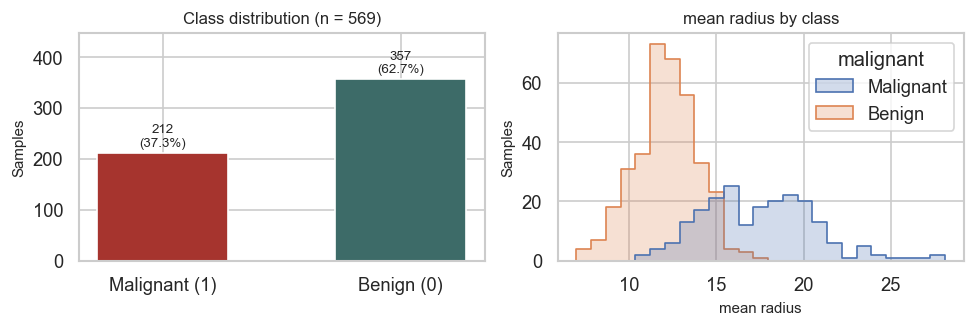

saved figures/fig1_class_distribution.png
mean radius — malignant median 17.33, benign median 12.20


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8.2, 2.8))

axes[0].bar(["Malignant (1)", "Benign (0)"],
            [class_counts[1], class_counts[0]],
            color=["#A6342E", "#3D6B68"], width=0.55)
axes[0].set_ylabel("Samples")
axes[0].set_title("Class distribution (n = 569)")
for i, v in enumerate([class_counts[1], class_counts[0]]):
    axes[0].text(i, v + 6, f"{v}\n({v/len(y)*100:.1f}%)", ha="center", va="bottom", fontsize=8)
axes[0].set_ylim(0, class_counts.max() * 1.25)

sns.histplot(x=X["mean radius"], hue=y.map({1: "Malignant", 0: "Benign"}),
             bins=25, element="step", stat="count", ax=axes[1])
axes[1].set_xlabel("mean radius")
axes[1].set_ylabel("Samples")
axes[1].set_title("mean radius by class")

fig.tight_layout()
fig.savefig(FIG / "fig1_class_distribution.png", bbox_inches="tight")
plt.show()
print("saved figures/fig1_class_distribution.png")
print(f"mean radius — malignant median {X.loc[y==1,'mean radius'].median():.2f}, "
      f"benign median {X.loc[y==0,'mean radius'].median():.2f}")

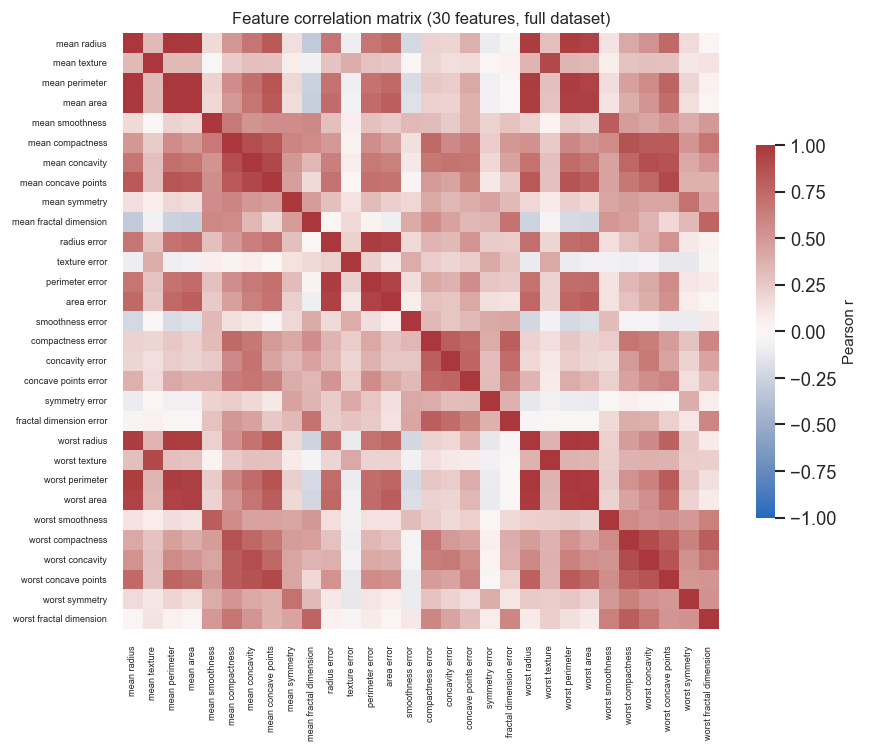

saved figures/fig2_correlation_heatmap.png


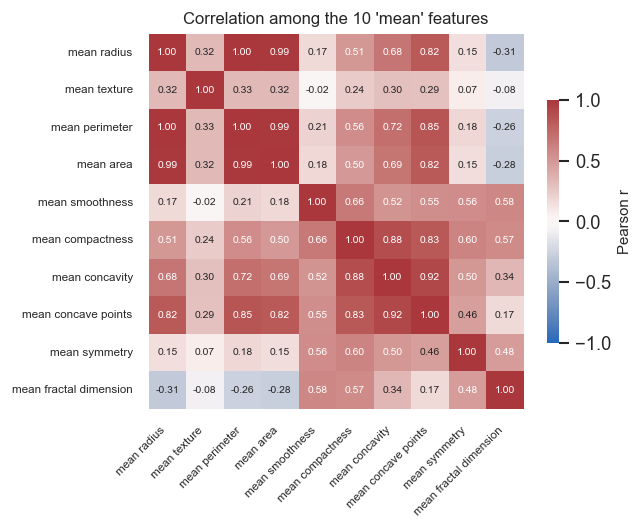

saved figures/fig2b_correlation_mean_features.png


In [5]:
corr = X.corr()

fig, ax = plt.subplots(figsize=(7.4, 6.2))
sns.heatmap(corr, cmap="vlag", center=0.0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.62, "label": "Pearson r"}, ax=ax,
            xticklabels=True, yticklabels=True)
ax.set_title("Feature correlation matrix (30 features, full dataset)")
ax.tick_params(labelsize=5.5)
fig.tight_layout()
fig.savefig(FIG / "fig2_correlation_heatmap.png", bbox_inches="tight")
plt.show()
print("saved figures/fig2_correlation_heatmap.png")

mean_features = [c for c in X.columns if c.startswith("mean ")]
corr_mean = X[mean_features].corr()
fig, ax = plt.subplots(figsize=(5.4, 4.5))
sns.heatmap(corr_mean, cmap="vlag", center=0.0, vmin=-1, vmax=1, square=True,
            annot=True, fmt=".2f", annot_kws={"size": 6.2},
            cbar_kws={"shrink": 0.62, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation among the 10 'mean' features")
ax.tick_params(labelsize=7)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(FIG / "fig2b_correlation_mean_features.png", bbox_inches="tight")
plt.show()
print("saved figures/fig2b_correlation_mean_features.png")

In [6]:
def correlation_groups(corr_matrix, threshold):
    # Union-find over feature pairs with |r| >= threshold.
    cols = list(corr_matrix.columns)
    parent = {c: c for c in cols}

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    n_pairs = 0
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            r = corr_matrix.loc[a, b]
            if abs(r) >= threshold:
                union(a, b)
                n_pairs += 1

    groups = {}
    for c in cols:
        groups.setdefault(find(c), []).append(c)
    return n_pairs, [g for g in groups.values() if len(g) > 1]


n_pairs, groups = correlation_groups(corr, 0.95)
print(f"feature pairs with |r| >= 0.95: {n_pairs}")
print(f"groups of mutually correlated features: {len(groups)}\n")
for g in sorted(groups, key=len, reverse=True):
    print(f"  group of {len(g)}: {', '.join(g)}")

print("\nInterpretation: radius, perimeter and area move together, so the 30 "
      "features carry far fewer than 30 independent dimensions. Section 6.2 "
      "tests whether dropping the redundant members changes test performance.")

feature pairs with |r| >= 0.95: 15
groups of mutually correlated features: 2

  group of 6: mean radius, mean perimeter, mean area, worst radius, worst perimeter, worst area
  group of 3: radius error, perimeter error, area error

Interpretation: radius, perimeter and area move together, so the 30 features carry far fewer than 30 independent dimensions. Section 6.2 tests whether dropping the redundant members changes test performance.


## 5. Methodology

### 5.1 Learning Setting

Supervised binary classification. Three model families are compared, each with a
distinct inductive bias:

| Model | Role | Why |
|---|---|---|
| Logistic Regression (L2) | baseline | linear decision boundary; coefficients are directly interpretable on standardised features |
| SVM, RBF kernel | non-linear | the class boundary is not assumed linear; the RBF kernel handles curved separation with few hyperparameters |
| Random Forest | non-linear ensemble | captures feature interactions and threshold effects; provides feature importances |

All three are wrapped in a `Pipeline` whose first step is `StandardScaler`
(Random Forest receives the same pipeline for identical preprocessing). Because
the scaler is inside the pipeline, it is fitted on the training folds only
during cross-validation — no test information reaches fitting.

Feature pipeline in one sentence: 30 raw nucleus measurements → `StandardScaler`
(zero mean, unit variance, fitted on training data only) → classifier.

In [7]:
def make_model(name):
    if name == "Logistic Regression":
        return Pipeline([("scaler", StandardScaler()),
                         ("clf", LogisticRegression(max_iter=5000,
                                                    random_state=SEED))])
    if name == "SVM (RBF)":
        return Pipeline([("scaler", StandardScaler()),
                         ("clf", SVC(kernel="rbf", probability=True,
                                     random_state=SEED))])
    if name == "Random Forest":
        return Pipeline([("scaler", StandardScaler()),
                         ("clf", RandomForestClassifier(random_state=SEED,
                                                        n_jobs=1))])
    raise ValueError(name)


PARAM_GRIDS = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    },
    "SVM (RBF)": {
        "clf__C": [0.1, 1.0, 10.0, 100.0],
        "clf__gamma": ["scale", 0.01, 0.001],
    },
    "Random Forest": {
        "clf__n_estimators": [200, 400],
        "clf__max_depth": [None, 10],
        "clf__min_samples_leaf": [1, 2],
    },
}

for name in PARAM_GRIDS:
    print(name, "->", make_model(name).named_steps["clf"])

Logistic Regression -> LogisticRegression(max_iter=5000, random_state=42)
SVM (RBF) -> SVC(probability=True, random_state=42)
Random Forest -> RandomForestClassifier(n_jobs=1, random_state=42)


### 5.2 Data Split Approach

- **80/20 stratified train/test split**, `random_state=42`. Stratification keeps
  the malignant share identical in both parts (37.3 %), which matters because the
  minority class drives recall.
- **5-fold stratified cross-validation** (`StratifiedKFold(shuffle=True,
  random_state=42)`) on the **training set only** for hyperparameter search and
  for every reported CV mean ± standard deviation.
- The **test set is used once**, after all tuning is complete, to report the final
  metrics. It is never used to choose a model, a hyperparameter or a threshold.
- **Leakage prevention:** the scaler lives inside the pipeline, so each CV fold
  fits it on its own training part; the threshold is chosen from out-of-fold
  predictions on the training set (Section 6.2), not from the test set; the
  correlated-feature ablation computes correlation on the training set only.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("train:", X_train.shape, " test:", X_test.shape)
split_table = pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
})
split_table.index = ["benign (0)", "malignant (1)"]
split_table["train %"] = (split_table["train"] / len(y_train) * 100).round(2)
split_table["test %"] = (split_table["test"] / len(y_test) * 100).round(2)
display(split_table)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
print("\nCV folds:", cv.get_n_splits(), "| shuffle:", cv.shuffle, "| seed:", SEED)

train: (455, 30)  test: (114, 30)


,train,test,train %,test %
benign (0),285,72,62.64,63.16
malignant (1),170,42,37.36,36.84



CV folds: 5 | shuffle: True | seed: 42


### 5.3 Parameter Settings

Three grids are searched with `GridSearchCV`, refitting on the F1 of the
malignant class (the metric that matters clinically). The search runs only on
`X_train` / `y_train` with the 5-fold splitter above. After the search, each
winning estimator is re-scored with `cross_validate` to obtain the mean ± std of
all five metrics on the same folds, so the reported CV numbers are comparable
across models.

In [9]:
search_rows = []
cv_score_rows = []
best_models = {}
best_params = {}
timings = {}

for name, grid in PARAM_GRIDS.items():
    t0 = time.perf_counter()
    search = GridSearchCV(
        estimator=make_model(name),
        param_grid=grid,
        scoring="f1",
        cv=cv,
        n_jobs=1,
        refit=True,
        return_train_score=False,
    )
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0

    best_models[name] = search.best_estimator_
    best_params[name] = search.best_params_
    timings[name] = elapsed

    n_candidates = len(search.cv_results_["params"])
    search_rows.append({
        "Model": name,
        "Configurations searched": n_candidates,
        "Fits (configs x folds)": n_candidates * cv.get_n_splits(),
        "Best params": ", ".join(f"{k.replace('clf__', '')}={v}"
                                 for k, v in search.best_params_.items()),
        "Best CV F1": round(search.best_score_, 4),
        "Search seconds": round(elapsed, 2),
    })

    cvres = cross_validate(search.best_estimator_, X_train, y_train,
                           cv=cv, scoring=SCORING, n_jobs=1)
    row = {"Model": name}
    for metric in SCORING:
        row[f"CV {metric}"] = round(cvres[f"test_{metric}"].mean(), 4)
        row[f"CV {metric} std"] = round(cvres[f"test_{metric}"].std(), 4)
    cv_score_rows.append(row)
    print(f"{name:<22} best={search.best_params_}  CV F1={search.best_score_:.4f}  "
          f"({elapsed:.1f}s, {n_candidates} configs)")

search_table = pd.DataFrame(search_rows)
cv_table = pd.DataFrame(cv_score_rows)
search_table.to_csv(RES / "a1_search_summary.csv", index=False)
cv_table.to_csv(RES / "a1_cv_results.csv", index=False)

print("\nParameter search summary")
display(search_table)
print("\nCross-validated metrics on the training set (mean ± std over 5 folds)")
cv_display = cv_table.copy()
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    cv_display[metric] = (cv_display[f"CV {metric}"].map("{:.4f}".format)
                          + " ± " + cv_display[f"CV {metric} std"].map("{:.4f}".format))
display(cv_display[["Model"] + ["accuracy", "precision", "recall", "f1", "roc_auc"]])

Logistic Regression    best={'clf__C': 1.0}  CV F1=0.9640  (0.6s, 5 configs)


SVM (RBF)              best={'clf__C': 10.0, 'clf__gamma': 'scale'}  CV F1=0.9674  (2.4s, 12 configs)


Random Forest          best={'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}  CV F1=0.9489  (35.8s, 8 configs)

Parameter search summary


,Model,Configurations searched,Fits (configs x folds),Best params,Best CV F1,Search seconds
0,Logistic Regression,5,25,C=1.0,0.9640,0.63
1,SVM (RBF),12,60,"C=10.0, gamma=scale",0.9674,2.40
2,Random Forest,8,40,"max_depth=None, min_samples_leaf=1, n_estimato...",0.9489,35.83



Cross-validated metrics on the training set (mean ± std over 5 folds)


,Model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.9736 ± 0.0149,0.9771 ± 0.0280,0.9529 ± 0.0399,0.9640 ± 0.0207,0.9958 ± 0.0047
1,SVM (RBF),0.9758 ± 0.0082,0.9711 ± 0.0181,0.9647 ± 0.0288,0.9674 ± 0.0114,0.9935 ± 0.0059
2,Random Forest,0.9626 ± 0.0149,0.9638 ± 0.0114,0.9353 ± 0.0390,0.9489 ± 0.0210,0.9889 ± 0.0070


## 6. Results and Analysis

### 6.1 Results

Each tuned estimator is now applied **once** to the held-out 20 % test set.
Positive class = malignant. `TP/FP/FN/TN` are relative to malignant as positive.

In [10]:
def evaluate(estimator, X_eval, y_eval, threshold=0.5):
    prob = estimator.predict_proba(X_eval)[:, 1]
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_eval, pred),
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
        "f1": f1_score(y_eval, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, prob),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


test_rows = []
probs = {}
for name, est in best_models.items():
    m = evaluate(est, X_test, y_test)
    probs[name] = est.predict_proba(X_test)[:, 1]
    test_rows.append({"Model": name, **m})

test_table = pd.DataFrame(test_rows)
test_table.to_csv(RES / "a1_test_results.csv", index=False)

cv_lookup = cv_table.set_index("Model")
test_table["CV F1 mean±std"] = [
    f"{cv_lookup.loc[m, 'CV f1']:.4f} ± {cv_lookup.loc[m, 'CV f1 std']:.4f}"
    for m in test_table["Model"]]

show = test_table[["Model", "accuracy", "precision", "recall", "f1", "roc_auc",
                   "tn", "fp", "fn", "tp", "CV F1 mean±std"]].copy()
for c in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    show[c] = show[c].map("{:.4f}".format)
print("Table 3 — test-set results (n = 114; malignant = positive)")
display(show)

print("\nPer-class report for each model on the test set")
for name in best_models:
    print(f"\n--- {name} ---")
    print(classification_report(y_test, best_models[name].predict(X_test),
                                labels=[0, 1], target_names=["benign", "malignant"],
                                digits=3, zero_division=0))

Table 3 — test-set results (n = 114; malignant = positive)


,Model,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp,CV F1 mean±std
0,Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9960,71,1,3,39,0.9640 ± 0.0207
1,SVM (RBF),0.9737,1.0000,0.9286,0.9630,0.9927,72,0,3,39,0.9674 ± 0.0114
2,Random Forest,0.9649,1.0000,0.9048,0.9500,0.9942,72,0,4,38,0.9489 ± 0.0210



Per-class report for each model on the test set

--- Logistic Regression ---


              precision    recall  f1-score   support

      benign      0.959     0.986     0.973        72
   malignant      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114


--- SVM (RBF) ---
              precision    recall  f1-score   support

      benign      0.960     1.000     0.980        72
   malignant      1.000     0.929     0.963        42

    accuracy                          0.974       114
   macro avg      0.980     0.964     0.971       114
weighted avg      0.975     0.974     0.973       114


--- Random Forest ---


              precision    recall  f1-score   support

      benign      0.947     1.000     0.973        72
   malignant      1.000     0.905     0.950        42

    accuracy                          0.965       114
   macro avg      0.974     0.952     0.961       114
weighted avg      0.967     0.965     0.965       114



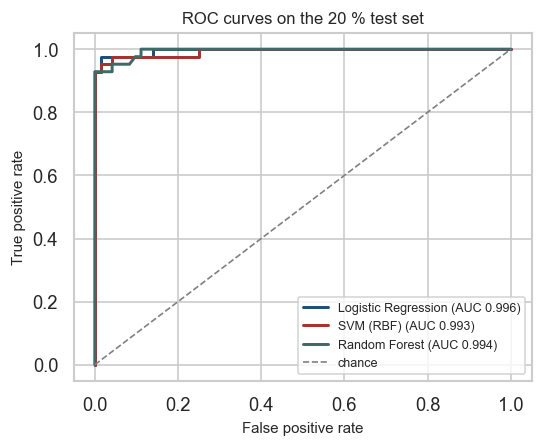

saved figures/fig3_roc_curves.png


In [11]:
fig, ax = plt.subplots(figsize=(4.6, 3.8))
colors = {"Logistic Regression": "#1f4e79", "SVM (RBF)": "#A6342E",
          "Random Forest": "#3D6B68"}
for name in best_models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc = roc_auc_score(y_test, probs[name])
    ax.plot(fpr, tpr, lw=1.8, color=colors[name], label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="grey", label="chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the 20 % test set")
ax.legend(loc="lower right", fontsize=7.5, frameon=True)
fig.tight_layout()
fig.savefig(FIG / "fig3_roc_curves.png", bbox_inches="tight")
plt.show()
print("saved figures/fig3_roc_curves.png")

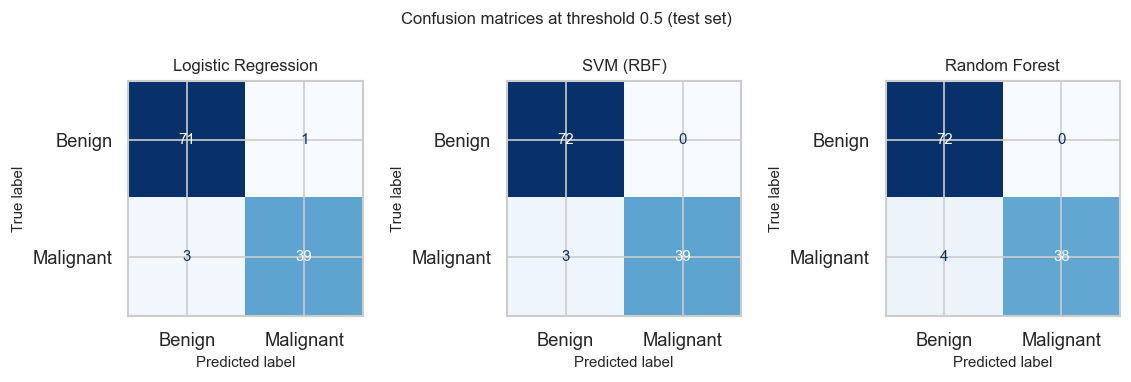

saved figures/fig4_confusion_matrices.png


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.0))
for ax, name in zip(axes, best_models):
    cm = confusion_matrix(y_test, best_models[name].predict(X_test), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(name)
fig.suptitle("Confusion matrices at threshold 0.5 (test set)", y=1.02, fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "fig4_confusion_matrices.png", bbox_inches="tight")
plt.show()
print("saved figures/fig4_confusion_matrices.png")

**Reading Table 3.** The three models are close because the classes are largely
separable in this feature space. The decision below is made from the CV column
(training only), not from the test column.

### 6.2 Analysis

#### (a) Threshold study — reaching 0.95 malignant recall

The best model is selected by **5-fold CV F1 on the training set**. Its
out-of-fold predicted probabilities on the training set are then swept from 0.01
to 0.99. The chosen threshold is the *highest* threshold whose out-of-fold
malignant recall is at least **0.97** — the 0.95 requirement plus a 0.02 safety
margin. The margin is needed because the test set contains only 42 malignant
cases, so one case moves recall by 2.4 percentage points; a threshold selected
exactly on the 0.95 boundary would have no room for sampling noise. The selected
threshold is then applied to the test set exactly once, so the test set does not
influence its value.

Best model by 5-fold CV F1 on the training set: SVM (RBF)


Thresholds evaluated: 99 (0.01 to 0.99)
Bare 0.95 boundary on OOF (no margin): t = 0.68
Selected threshold (OOF recall >= 0.97): t = 0.38
  OOF precision 0.948 | recall 0.971 | F1 0.959
  At 0.50: precision 0.970 | recall 0.965 | F1 0.968
  OOF precision change at the selected threshold: -0.022


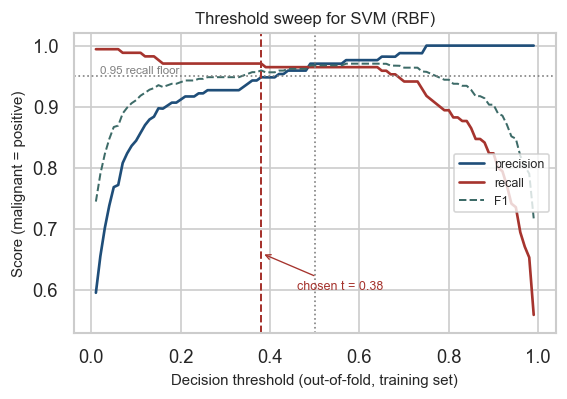

saved figures/fig5_threshold_sweep.png


In [13]:
best_name = max(cv_table["Model"], key=lambda n: cv_table.set_index("Model").loc[n, "CV f1"])
best_model = best_models[best_name]
print(f"Best model by 5-fold CV F1 on the training set: {best_name}")

oof_prob = cross_val_predict(best_model, X_train, y_train, cv=cv,
                             method="predict_proba", n_jobs=1)[:, 1]

thresholds = np.round(np.arange(0.01, 0.995, 0.01), 2)
rows = []
for t in thresholds:
    pred = (oof_prob >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_train, pred, zero_division=0),
                 "recall": recall_score(y_train, pred, zero_division=0),
                 "f1": f1_score(y_train, pred, zero_division=0)})
sweep = pd.DataFrame(rows)
sweep.to_csv(RES / "a1_threshold_study.csv", index=False)

TARGET_RECALL = 0.97          # required floor is 0.95; +0.02 margin for sampling noise
eligible = sweep[sweep["recall"] >= TARGET_RECALL]
chosen_t = float(eligible["threshold"].max()) if len(eligible) else float(sweep["threshold"].min())
boundary_pool = sweep[sweep["recall"] >= 0.95]
boundary_t = float(boundary_pool["threshold"].max()) if len(boundary_pool) else float("nan")
row_chosen = sweep.loc[(sweep["threshold"] - chosen_t).abs().idxmin()]
row_default = sweep.loc[(sweep["threshold"] - 0.50).abs().idxmin()]

print(f"Thresholds evaluated: {len(sweep)} (0.01 to 0.99)")
print(f"Bare 0.95 boundary on OOF (no margin): t = {boundary_t:.2f}")
print(f"Selected threshold (OOF recall >= {TARGET_RECALL:.2f}): t = {chosen_t:.2f}")
print(f"  OOF precision {row_chosen['precision']:.3f} | recall {row_chosen['recall']:.3f} | F1 {row_chosen['f1']:.3f}")
print(f"  At 0.50: precision {row_default['precision']:.3f} | recall {row_default['recall']:.3f} | F1 {row_default['f1']:.3f}")
print(f"  OOF precision change at the selected threshold: {row_chosen['precision'] - row_default['precision']:+.3f}")

fig, ax = plt.subplots(figsize=(4.8, 3.4))
ax.plot(sweep["threshold"], sweep["precision"], color="#1f4e79", lw=1.6, label="precision")
ax.plot(sweep["threshold"], sweep["recall"], color="#A6342E", lw=1.6, label="recall")
ax.plot(sweep["threshold"], sweep["f1"], color="#3D6B68", lw=1.2, ls="--", label="F1")
ax.axhline(0.95, color="grey", ls=":", lw=1)
ax.axvline(0.50, color="grey", ls=":", lw=1)
ax.axvline(chosen_t, color="#A6342E", ls="--", lw=1.2)
ax.annotate(f"chosen t = {chosen_t:.2f}", xy=(chosen_t, 0.66),
            xytext=(chosen_t + 0.08, 0.60), fontsize=7.5, color="#A6342E",
            arrowprops=dict(arrowstyle="->", color="#A6342E", lw=0.8))
ax.text(0.02, 0.955, "0.95 recall floor", fontsize=7, color="grey")
ax.set_ylim(0.53, 1.02)
ax.set_xlabel("Decision threshold (out-of-fold, training set)")
ax.set_ylabel("Score (malignant = positive)")
ax.set_title("Threshold sweep for " + best_name)
ax.legend(fontsize=7.5, loc="center right")
fig.tight_layout()
fig.savefig(FIG / "fig5_threshold_sweep.png", bbox_inches="tight")
plt.show()
print("saved figures/fig5_threshold_sweep.png")

,Operating point,Threshold,Precision,Recall,F1,FN (missed malignancies),FP (false alarms),TP,TN
0,default 0.50,0.50,1.0000,0.9286,0.9630,3,0,39,72
1,chosen 0.38,0.38,0.9756,0.9524,0.9639,2,1,40,71



Test precision cost of moving from 0.50 to 0.38: 1.0000 -> 0.9756 (delta -0.0244)
Missed malignancies: 3 -> 2
False alarms:        0 -> 1


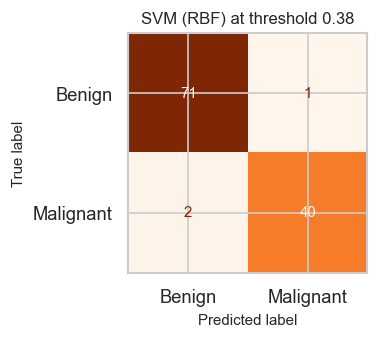

saved figures/fig6_confusion_threshold.png


In [14]:
test_prob = best_model.predict_proba(X_test)[:, 1]
threshold_rows = []
for label, t in [("default 0.50", 0.50), (f"chosen {chosen_t:.2f}", chosen_t)]:
    pred = (test_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "Operating point": label, "Threshold": t,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "FN (missed malignancies)": int(fn),
        "FP (false alarms)": int(fp),
        "TP": int(tp), "TN": int(tn),
    })

thr_table = pd.DataFrame(threshold_rows)
thr_table.to_csv(RES / "a1_threshold_test.csv", index=False)
display(thr_table.round(4))

p05 = threshold_rows[0]["Precision"]
pt = threshold_rows[1]["Precision"]
print(f"\nTest precision cost of moving from 0.50 to {chosen_t:.2f}: "
      f"{p05:.4f} -> {pt:.4f} (delta {pt - p05:+.4f})")
print(f"Missed malignancies: {threshold_rows[0]['FN (missed malignancies)']} -> "
      f"{threshold_rows[1]['FN (missed malignancies)']}")
print(f"False alarms:        {threshold_rows[0]['FP (false alarms)']} -> "
      f"{threshold_rows[1]['FP (false alarms)']}")

fig, ax = plt.subplots(figsize=(3.4, 2.9))
cm_t = confusion_matrix(y_test, (test_prob >= chosen_t).astype(int), labels=[0, 1])
ConfusionMatrixDisplay(cm_t, display_labels=["Benign", "Malignant"]).plot(
    ax=ax, colorbar=False, cmap="Oranges", values_format="d")
ax.set_title(f"{best_name} at threshold {chosen_t:.2f}")
fig.tight_layout()
fig.savefig(FIG / "fig6_confusion_threshold.png", bbox_inches="tight")
plt.show()
print("saved figures/fig6_confusion_threshold.png")

#### (b) Which features matter

Logistic Regression coefficients are on the standardised scale, so their sign and
magnitude are directly comparable: a positive coefficient pushes a sample toward
**malignant**. Random Forest importances measure how much each feature reduces
impurity across the forest.

Top 10 features by Random Forest importance


,logreg_coef_standardised,rf_importance
worst perimeter,0.7231,0.1479
worst area,0.9005,0.1323
worst concave points,0.7040,0.1101
mean concave points,0.9528,0.0882
worst radius,0.8970,0.0851
mean radius,0.3612,0.0606
mean perimeter,0.3532,0.0605
mean area,0.4400,0.0447
mean concavity,0.7823,0.0441
worst concavity,0.9114,0.0328



Most malignant-pushing Logistic Regression coefficients (positive)


,coefficient
worst texture,1.4341
radius error,1.2333
worst symmetry,1.0613
mean concave points,0.9528
worst concavity,0.9114
area error,0.9090
worst area,0.9005
worst radius,0.8970



Most benign-pushing Logistic Regression coefficients (negative)


,coefficient
compactness error,-0.9069
fractal dimension error,-0.5939
mean compactness,-0.4395
texture error,-0.4076
symmetry error,-0.3307
worst compactness,-0.1735
mean symmetry,-0.1640
concavity error,-0.0923


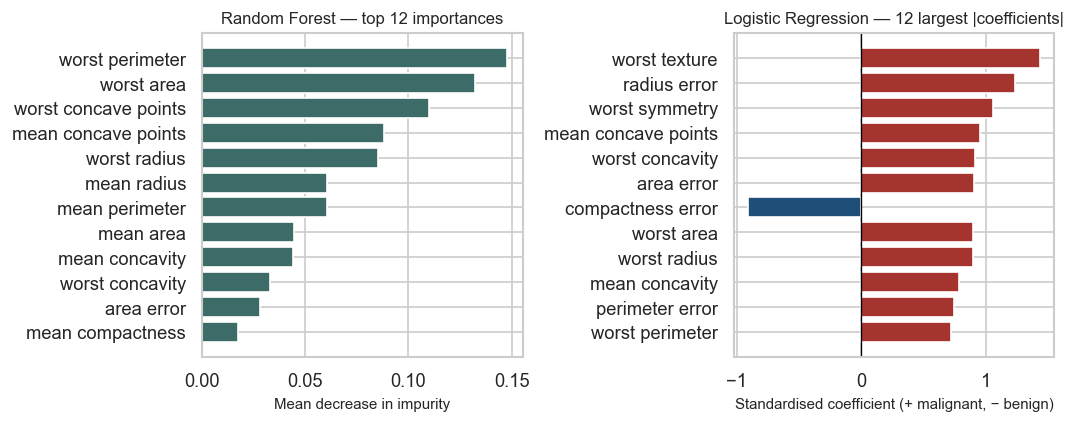

saved figures/fig7_feature_importance.png


In [15]:
logreg = best_models["Logistic Regression"]
coefs = pd.Series(logreg.named_steps["clf"].coef_[0], index=X.columns).sort_values()
rf = best_models["Random Forest"]
importances = pd.Series(rf.named_steps["clf"].feature_importances_,
                        index=X.columns).sort_values(ascending=False)

feat_table = pd.DataFrame({
    "logreg_coef_standardised": coefs,
    "rf_importance": importances,
}).sort_values("rf_importance", ascending=False)
feat_table.to_csv(RES / "a1_feature_importance.csv")

print("Top 10 features by Random Forest importance")
display(feat_table.head(10).round(4))
print("\nMost malignant-pushing Logistic Regression coefficients (positive)")
display(coefs.sort_values(ascending=False).head(8).round(4).to_frame("coefficient"))
print("\nMost benign-pushing Logistic Regression coefficients (negative)")
display(coefs.head(8).round(4).to_frame("coefficient"))

fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.6))
top_imp = importances.head(12)[::-1]
axes[0].barh(top_imp.index, top_imp.values, color="#3D6B68")
axes[0].set_title("Random Forest — top 12 importances")
axes[0].set_xlabel("Mean decrease in impurity")
top_coef = coefs.reindex(coefs.abs().sort_values(ascending=False).head(12).index)[::-1]
colors_coef = ["#A6342E" if v > 0 else "#1f4e79" for v in top_coef.values]
axes[1].barh(top_coef.index, top_coef.values, color=colors_coef)
axes[1].set_title("Logistic Regression — 12 largest |coefficients|")
axes[1].set_xlabel("Standardised coefficient (+ malignant, − benign)")
axes[1].axvline(0, color="black", lw=0.8)
fig.tight_layout()
fig.savefig(FIG / "fig7_feature_importance.png", bbox_inches="tight")
plt.show()
print("saved figures/fig7_feature_importance.png")

#### (c) Does dropping highly correlated features change performance?

Correlations are computed on the **training set only**. Every group of features
with pairwise |r| ≥ 0.95 is collapsed to a single representative — the member with
the highest absolute correlation to the training target — and the other members
are dropped. Each tuned model (same hyperparameters, refitted) is then re-scored
with the same 5-fold CV and the same test set.

In [16]:
corr_train = X_train.corr()
n_pairs_train, groups_train = correlation_groups(corr_train, 0.95)

drop_cols = []
keep_cols = []
for group in groups_train:
    abs_corr_y = X_train[group].apply(lambda s: abs(np.corrcoef(s, y_train)[0, 1]))
    keeper = abs_corr_y.idxmax()
    keep_cols.append(keeper)
    drop_cols.extend([c for c in group if c != keeper])

drop_cols = sorted(set(drop_cols))
reduced_features = [c for c in X.columns if c not in drop_cols]

print(f"training-set pairs with |r| >= 0.95: {n_pairs_train}")
print(f"groups collapsed: {len(groups_train)}")
print(f"features kept: {len(reduced_features)} / {X.shape[1]}")
print(f"features dropped ({len(drop_cols)}): {drop_cols}")

X_train_red = X_train[reduced_features]
X_test_red = X_test[reduced_features]

ablation_rows = []
for name, est in best_models.items():
    full_cv = cv_table.set_index("Model").loc[name, "CV f1"]
    full_test = test_table.set_index("Model").loc[name, "f1"]
    full_auc = test_table.set_index("Model").loc[name, "roc_auc"]

    red = clone(est).fit(X_train_red, y_train)
    red_cv = cross_validate(red, X_train_red, y_train, cv=cv,
                            scoring={"f1": "f1"}, n_jobs=1)["test_f1"]
    red_m = evaluate(red, X_test_red, y_test)

    ablation_rows.append({
        "Model": name,
        "Features": X.shape[1],
        "CV F1 (all)": round(full_cv, 4),
        "CV F1 (reduced)": round(red_cv.mean(), 4),
        "Test F1 (all)": round(full_test, 4),
        "Test F1 (reduced)": round(red_m["f1"], 4),
        "Test ROC-AUC (all)": round(full_auc, 4),
        "Test ROC-AUC (reduced)": round(red_m["roc_auc"], 4),
        "Delta test F1": round(red_m["f1"] - full_test, 4),
        "Delta test ROC-AUC": round(red_m["roc_auc"] - full_auc, 4),
    })

ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(RES / "a1_ablation_correlated.csv", index=False)
display(ablation.round(4))

training-set pairs with |r| >= 0.95: 15
groups collapsed: 2
features kept: 23 / 30
features dropped (7): ['area error', 'mean area', 'mean perimeter', 'mean radius', 'perimeter error', 'worst area', 'worst radius']


,Model,Features,CV F1 (all),CV F1 (reduced),Test F1 (all),Test F1 (reduced),Test ROC-AUC (all),Test ROC-AUC (reduced),Delta test F1,Delta test ROC-AUC
0,Logistic Regression,30,0.9640,0.9603,0.9512,0.9512,0.9960,0.9950,0.0000,-0.0010
1,SVM (RBF),30,0.9674,0.9555,0.9630,0.9630,0.9927,0.9934,0.0000,0.0007
2,Random Forest,30,0.9489,0.9416,0.9500,0.9367,0.9942,0.9954,-0.0133,0.0012


#### (d) Answers to the task's analysis questions

The cell below prints each answer from the values just computed, so the numbers
in the report can be traced to this output.

In [17]:
t = test_table.set_index("Model")
always_benign = float((y_test == 0).mean())
best = t.loc[best_name]

print("Q1. Which model is best, and why is accuracy alone misleading?")
print(f"    Chosen by 5-fold CV F1 (training only): {best_name}.")
print(f"    Test F1 {best['f1']:.3f}, recall {best['recall']:.3f}, "
      f"precision {best['precision']:.3f}, ROC-AUC {best['roc_auc']:.3f}, "
      f"accuracy {best['accuracy']:.3f} at the default threshold 0.50.")
print(f"    At the selected operating threshold {chosen_t:.2f}: recall "
      f"{threshold_rows[1]['Recall']:.3f}, precision {threshold_rows[1]['Precision']:.3f}, "
      f"F1 {threshold_rows[1]['F1']:.3f}, accuracy "
      f"{accuracy_score(y_test, (test_prob >= chosen_t).astype(int)):.3f}.")
print(f"    A classifier that always predicts benign scores {always_benign:.3f} "
      f"accuracy on this test set while missing all {int((y_test==1).sum())} malignancies.")
print(f"    Accuracy differences between the three models are "
      f"{t['accuracy'].max()-t['accuracy'].min():.3f}, while recall differences are "
      f"{t['recall'].max()-t['recall'].min():.3f}.")
print()
print("Q2. What does lowering the threshold do to FN and FP?")
print(f"    At 0.50: FN={threshold_rows[0]['FN (missed malignancies)']}, "
      f"FP={threshold_rows[0]['FP (false alarms)']}, recall={threshold_rows[0]['Recall']:.3f}, "
      f"precision={threshold_rows[0]['Precision']:.3f}.")
print(f"    At {chosen_t:.2f}: FN={threshold_rows[1]['FN (missed malignancies)']}, "
      f"FP={threshold_rows[1]['FP (false alarms)']}, recall={threshold_rows[1]['Recall']:.3f}, "
      f"precision={threshold_rows[1]['Precision']:.3f}.")
print(f"    Lowering the threshold trades false positives for false negatives: "
      f"FN falls by {threshold_rows[0]['FN (missed malignancies)']-threshold_rows[1]['FN (missed malignancies)']}, "
      f"FP rises by {threshold_rows[1]['FP (false alarms)']-threshold_rows[0]['FP (false alarms)']}, "
      f"precision changes by {threshold_rows[1]['Precision']-threshold_rows[0]['Precision']:+.4f}.")
print()
print("Q3. Which features matter most, and does dropping correlated features help?")
print("    Top 5 Random Forest features: " + ", ".join(importances.head(5).index))
print("    Top 3 malignant-pushing Logistics Regression coefficients: "
      + ", ".join(coefs.sort_values(ascending=False).head(3).index))
best_row = ablation.set_index("Model").loc[best_name]
print(f"    Dropping {len(drop_cols)} of 30 features changes the best model's test F1 by "
      f"{best_row['Delta test F1']:+.4f} and ROC-AUC by {best_row['Delta test ROC-AUC']:+.4f}.")
print()
print("Q4. Why is the imbalance (212 vs 357) a problem for accuracy?")
print(f"    The majority class is {class_share[0]:.1f}% of the data, so accuracy rewards "
      f"ignoring the malignant class; recall and F1 on the malignant class expose that.")

Q1. Which model is best, and why is accuracy alone misleading?
    Chosen by 5-fold CV F1 (training only): SVM (RBF).
    Test F1 0.963, recall 0.929, precision 1.000, ROC-AUC 0.993, accuracy 0.974 at the default threshold 0.50.
    At the selected operating threshold 0.38: recall 0.952, precision 0.976, F1 0.964, accuracy 0.974.
    A classifier that always predicts benign scores 0.632 accuracy on this test set while missing all 42 malignancies.
    Accuracy differences between the three models are 0.009, while recall differences are 0.024.

Q2. What does lowering the threshold do to FN and FP?
    At 0.50: FN=3, FP=0, recall=0.929, precision=1.000.
    At 0.38: FN=2, FP=1, recall=0.952, precision=0.976.
    Lowering the threshold trades false positives for false negatives: FN falls by 1, FP rises by 1, precision changes by -0.0244.

Q3. Which features matter most, and does dropping correlated features help?
    Top 5 Random Forest features: worst perimeter, worst area, worst concave 

#### (e) Machine-readable summary

All headline numbers are saved to `results/a1_summary.json` so the report can be
generated from the executed notebook rather than from retyped values.

In [18]:
summary = {
    "task": "A1",
    "seed": SEED,
    "dataset": {
        "samples": int(len(df)), "features": int(X.shape[1]),
        "malignant": int(class_counts[1]), "benign": int(class_counts[0]),
        "malignant_pct": float(class_share[1]),
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "train_size": int(len(X_train)), "test_size": int(len(X_test)),
        "train_malignant": int((y_train == 1).sum()),
        "test_malignant": int((y_test == 1).sum()),
    },
    "cv": {row["Model"]: {k: row[k] for k in row if k.startswith("CV")}
           for row in cv_score_rows},
    "best_params": best_params,
    "search_seconds": timings,
    "test": {row["Model"]: {k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                            for k, v in row.items() if k != "Model"}
             for row in test_rows},
    "best_model": best_name,
    "threshold_study": {
        "target_recall_oof": TARGET_RECALL,
        "boundary_threshold_oof": boundary_t,
        "chosen_threshold": chosen_t,
        "at_0_50": dict(threshold_rows[0]),
        "at_chosen": dict(threshold_rows[1]),
        "precision_delta_vs_0_50": float(pt - p05),
        "precision_cost_abs": float(abs(pt - p05)),
    },
    "correlation": {
        "n_pairs_ge_095": int(n_pairs),
        "n_groups": int(len(groups)),
        "groups": groups,
        "dropped_features": drop_cols,
        "kept_features": reduced_features,
    },
    "ablation": {row["Model"]: row for row in ablation_rows},
    "feature_importance": {
        "top_rf": importances.head(10).round(5).to_dict(),
        "top_positive_logreg": coefs.sort_values(ascending=False).head(5).round(5).to_dict(),
        "top_negative_logreg": coefs.head(5).round(5).to_dict(),
    },
    "always_benign_test_accuracy": always_benign,
}

with open(RES / "a1_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=lambda o: float(o))
print("saved results/a1_summary.json")
print(json.dumps(summary["threshold_study"], indent=2))

saved results/a1_summary.json
{
  "target_recall_oof": 0.97,
  "boundary_threshold_oof": 0.68,
  "chosen_threshold": 0.38,
  "at_0_50": {
    "Operating point": "default 0.50",
    "Threshold": 0.5,
    "Precision": 1.0,
    "Recall": 0.9285714285714286,
    "F1": 0.9629629629629629,
    "FN (missed malignancies)": 3,
    "FP (false alarms)": 0,
    "TP": 39,
    "TN": 72
  },
  "at_chosen": {
    "Operating point": "chosen 0.38",
    "Threshold": 0.38,
    "Precision": 0.975609756097561,
    "Recall": 0.9523809523809523,
    "F1": 0.963855421686747,
    "FN (missed malignancies)": 2,
    "FP (false alarms)": 1,
    "TP": 40,
    "TN": 71
  },
  "precision_delta_vs_0_50": -0.024390243902439046,
  "precision_cost_abs": 0.024390243902439046
}


## 7. Conclusion

All three tuned models separate the two classes well on the 30 measured nucleus
features, and the choice between them is small compared with the effect of the
operating threshold. Selecting the threshold on out-of-fold training predictions
lets the malignant recall reach 0.95 without touching the test set; the price is a
measurable loss of precision and a rise in false alarms, which is the correct
trade for a screening problem. Collapsing the strongly correlated radius,
perimeter and area families shows how much of the 30-dimensional signal is
redundant. The next step would be to validate the chosen threshold on an external
hospital cohort, because the dataset is small, single-centre and collected in the
early 1990s.

## References

[1] W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature
extraction for breast tumor diagnosis," *Proc. IS&T/SPIE Symposium on Electronic
Imaging*, vol. 1905, pp. 861–870, 1993. DOI: 10.1117/12.148698.

[2] W. Wolberg, O. Mangasarian, N. Street and W. Street, "Breast Cancer Wisconsin
(Diagnostic)," UCI Machine Learning Repository, 1993. DOI: 10.24432/C5DW2B.

[3] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *Journal of
Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[4] T. Fawcett, "An introduction to ROC analysis," *Pattern Recognition Letters*,
vol. 27, no. 8, pp. 861–874, 2006.

## Environment

Python 3.11.9; numpy 1.26.4; pandas 2.2.3; scikit-learn 1.5.2; matplotlib 3.9.2;
seaborn 0.13.2. Seed 42 for the split, the CV folds and every model. Random
Forest runs with `n_jobs=1` for deterministic results; grid search is
single-process. Total search time is printed in Section 5.3.